In [1]:
!pip3 install scanpy==1.9.3

  Using cached scanpy-1.9.3-py3-none-any.whl.metadata (6.1 kB)
  Using cached anndata-0.10.6-py3-none-any.whl.metadata (6.6 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached tqdm-4.66.2-py3-none-any.whl.metadata (57 kB)
  Using cached statsmodels-0.14.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (9.5 kB)
  Using cached patsy-0.5.6-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached natsort-8.4.0-py3-none-any.whl.metadata (21 kB)
  Using cached session_info-1.0.0-py3-none-any.whl
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.50.0-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (159 kB)
  Using cached kiwisolver-1.4.5-cp310-cp310-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (6.4 kB)
  Using cached stdlib_list-0.10.0-py3-none-any.whl.metadata (3.3 kB)
Using cached scanpy-1.9.3-py3-none-any.whl (2.0 MB)
Using cached anndata-0.10.6-py3-none-any.whl (122 kB

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

  Using cached scib_metrics-0.5.1-py3-none-any.whl.metadata (8.3 kB)
  Using cached chex-0.1.86-py3-none-any.whl.metadata (17 kB)
  Using cached igraph-0.11.4-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.9 kB)
  Using cached plottable-0.1.5-py3-none-any.whl.metadata (3.2 kB)
  Using cached texttable-1.7.0-py2.py3-none-any.whl.metadata (9.8 kB)
Using cached scib_metrics-0.5.1-py3-none-any.whl (36 kB)
Using cached igraph-0.11.4-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.3 MB)
Using cached chex-0.1.86-py3-none-any.whl (98 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 4.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 MB 27.1 MB/s eta 0:00:0000:0100:01
Using cached plottable-0.1.5-py3-none-any.whl (24 kB)
Using cached texttable-1.7.0-py2.py3-none-any.whl (10 kB)
  Attempting uninstall: jax
    Found existing installation: jax 0.4.6
    Uninstalling jax-0.4.6:
      Successfully uninstalled jax-0.4.6


In [3]:
!pip3 install leidenalg==0.10.1

  Using cached leidenalg-0.10.1-cp38-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (10 kB)
  Using cached igraph-0.10.8-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.8 kB)
Using cached leidenalg-0.10.1-cp38-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.0 MB)
Using cached igraph-0.10.8-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.3 MB)
  Attempting uninstall: igraph
    Found existing installation: igraph 0.11.4
    Uninstalling igraph-0.11.4:
      Successfully uninstalled igraph-0.11.4


In [4]:
!pip3 install louvain==0.8.1

  Using cached louvain-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.5 kB)
Using cached louvain-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (1.1 MB)


## Imports

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-04-05 01:58:22.712398: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-05 01:58:22.712466: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-05 01:58:22.715763: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [6]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [7]:
#set variables to subset data
dataset="Santamaria"
condition="AS"
mode="sample"

## load and prep Data

### load and prep embedding 

In [8]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/Santamaria_mapped_emb_subsetted_and_processed.h5ad")

In [9]:
adata[adata.obs.dataset==dataset].obs["sample"]

AS_AS_ENTIRE-1-13-S1_AAACCCAAGAAGTGTT-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGACAGCGT-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGCAGAA-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGGGTAA-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGGCCTTCG-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
                                                                    ...                     
Estonia_EST-41-G2-EPST109_TTTGGAGTCGACATTG-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGGTTGTTATGTCG-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGAGGGTAGCT-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGTCCATTCAT-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGTCGGACTGC-1    run_count_0192_ASH-21G

In [10]:
#correct endometrial pathology for group=WOI Control as they are control
adata[adata.obs.dataset=="Santamaria"].obs['Group']
adata.obs.loc[adata.obs.Group=="WOI Control",'Endometrial_pathology']="C"

In [11]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [12]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['ref_or_query']=="ref") ].copy()

In [13]:
#subset to condition
adata=adata[(adata.obs['Endometrial_pathology']== condition )|(adata.obs['ref_or_query']=="ref") ].copy()

In [14]:
adata.obs.dataset

HCA_A_RepT_RNA13247830_AAACCTGAGCGATGAC-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGAGCTAGGCA-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCACCAACCG-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCACCTGGTG-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCATAGAAAC-Mareckova     Mareckova
                                                        ...    
AS_AS_ENTIRE-1-12-E1_TTTGTTGAGGCACCAA-1              Santamaria
AS_AS_ENTIRE-1-12-E1_TTTGTTGGTCCAAATC-1              Santamaria
AS_AS_ENTIRE-1-12-E1_TTTGTTGGTGCGAACA-1              Santamaria
AS_AS_ENTIRE-1-12-E1_TTTGTTGTCAAGTTGC-1              Santamaria
AS_AS_ENTIRE-1-12-E1_TTTGTTGTCTACTATC-1              Santamaria
Name: dataset, Length: 208770, dtype: category
Categories (7, object): ['GarciaAlonso', 'Huang', 'Lai', 'Mareckova', 'Santamaria', 'Tan', 'Wang']

### improvise on subject ID (Specific to this dataset)

Since we don't have an explicit subject_id, 
we improvise by combining three features age, genotype and group to hopefully get the individual donors. We have 33 particpants in HECA and 6 controls in Santamaria + 9 patients in Santamaria

In [15]:
donors = adata.obs.groupby(["dataset","Age","genotype","Group"]).agg({"sample":"nunique"}).reset_index()
donors.loc[(donors["sample"]>0)]

,dataset,Age,genotype,Group,sample
299,GarciaAlonso,23,A30,Ctrl_whole_uterus,2
610,GarciaAlonso,26,E2,Ctrl_Superficial,2
613,GarciaAlonso,26,E3,Ctrl_Superficial,2
754,GarciaAlonso,29,E1,Ctrl_Superficial,2
1472,GarciaAlonso,35,A13,Ctrl_whole_uterus,2
2995,Huang,24,GSM6605440,Ctrl_Superficial,1
3280,Huang,29,GSM6605437,Ctrl_Superficial,1
3724,Huang,32,GSM6605438,Ctrl_Superficial,1
3874,Huang,33,GSM6605439,Ctrl_Superficial,1
7387,Lai,nan,GSM5572238,Ctrl_Superficial,1


In [16]:
len(donors.loc[(donors["sample"]>0)])

32

We don't seem to find one donor from the HECA atlas. The samples from Santameria are all from differnet donors, so we set HECA donors to the one we found and Santamaria donors to just the samples. If additional information is availible, we can recalculate the metric.

In [17]:
adata.obs["donor_id"]=np.nan

In [18]:
for i,d in enumerate(donors.iterrows()) :
    adata.obs.loc[(adata.obs.dataset==d[1]["dataset"])&
                  (adata.obs.Age==d[1]["Age"])&
                  (adata.obs.genotype==d[1]["genotype"])&
                 (adata.obs.Group==d[1]["Group"]),"donor_id"]=f'subject_{i}'

In [19]:
for i,d in enumerate(adata[adata.obs.dataset==dataset].obs["sample"].cat.categories):
    adata.obs.loc[(adata.obs["sample"]==d,"donor_id")]=f'query_subject_{i}'


### load and prep query_counts

In [20]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/Asherman_syndrome_wo_wang.h5ad")

In [21]:
adata_query

AnnData object with n_obs × n_vars = 59301 × 33538
    obs: 'sample', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'Group', 'phase', 'menstrual_cycle_day', 'principal_cell_types', 'celltype', 'dataset', 'Endometrial_pathology'
    var: 'features'

In [22]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [23]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [24]:
adata_query

AnnData object with n_obs × n_vars = 40336 × 33538
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden', 'donor_id'
    var: 'features'

In [25]:
#set obsm layer X_scanvi to embedding
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

## run metrics

In [26]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "sample"

In [27]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 153.120 s
Time to complete lisi_batch: 4.239 s
Time to complete kbet_batch: 1.104 s


In [28]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 4.577 s
Time to complete lisi_query_donor: 0.975 s
Time to complete wiq_knn_corr: 265.452 s


In [29]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 145.987 s


In [30]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [31]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAAGTGTT-1,0.091938,0.0,0.183383,0.247688,0.000000
AS_AS_ENTIRE-1-13-S1_AAACCCAAGACAGCGT-1,0.067487,0.0,0.056516,0.131320,0.706348
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGCAGAA-1,0.044433,0.0,0.008629,0.252481,2.887170
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGGGTAA-1,0.005977,0.0,0.012711,0.225746,0.540703
AS_AS_ENTIRE-1-13-S1_AAACCCAAGGCCTTCG-1,0.076775,0.0,0.039643,0.261013,5.000000
...,...,...,...,...,...
AS_AS_ENTIRE-1-12-E1_TTTGTTGAGGCACCAA-1,0.026764,0.0,0.024236,0.294718,5.000000
AS_AS_ENTIRE-1-12-E1_TTTGTTGGTCCAAATC-1,0.015688,0.0,0.017689,0.210994,0.129283
AS_AS_ENTIRE-1-12-E1_TTTGTTGGTGCGAACA-1,0.078526,0.0,0.089405,0.369855,0.000000
AS_AS_ENTIRE-1-12-E1_TTTGTTGTCAAGTTGC-1,0.028578,0.0,0.019255,0.192617,2.332678


In [32]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [33]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [34]:
sc.pp.neighbors(adata,n_neighbors=50)

In [35]:
sc.tl.umap(adata)

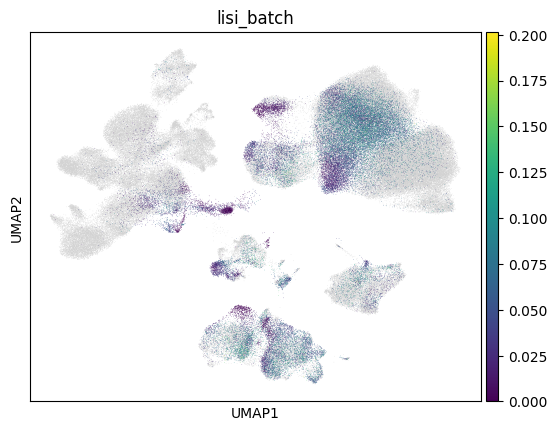

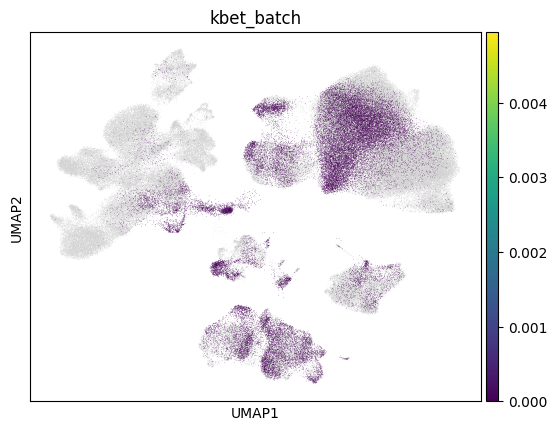

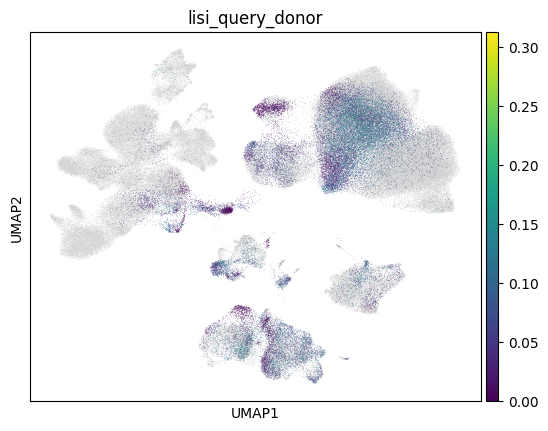

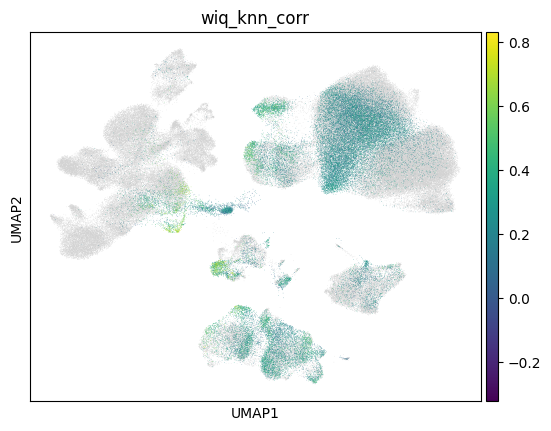

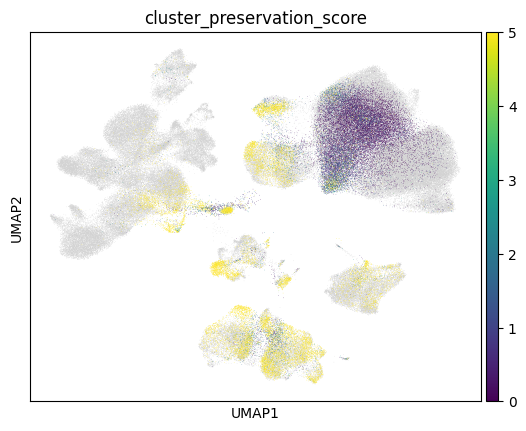

In [37]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs['ref_or_query']=="ref",metric]=np.nan
    sc.pl.umap(adata,color=metric)